In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import sys
sys.path.append("src")

from signal_generation import (
    generate_bpsk,
    generate_qpsk,
    generate_16qam
)

np.random.seed(42)

print("Libraries and signal generators loaded successfully!")

BPSK generated: 1000
QPSK generated: 1000
16-QAM generated: 1000
Libraries and signal generators loaded successfully!


In [2]:
def generate_awgn(n_samples, noise_power):

    noise = np.sqrt(noise_power / 2) * (
        np.random.randn(n_samples) +
        1j * np.random.randn(n_samples)
    )

    return noise

In [3]:
def generate_h0(n_samples, noise_power=1.0):

    noise = generate_awgn(n_samples, noise_power)

    return noise

In [4]:
def generate_h1(signal, noise_power):

    noise = generate_awgn(len(signal), noise_power)

    received_signal = signal + noise

    return received_signal

In [5]:
n_samples = 10000

# Generate H0: noise only
h0_signal = generate_h0(n_samples, noise_power=1.0)

# Generate H1: QPSK signal + noise
qpsk = generate_qpsk(n_samples)

h1_signal = generate_h1(qpsk, noise_power=1.0)

print("H0 signal power:",
      np.mean(np.abs(h0_signal)**2))

print("H1 signal power:",
      np.mean(np.abs(h1_signal)**2))

print("H0 samples:", len(h0_signal))
print("H1 samples:", len(h1_signal))

H0 signal power: 1.004472555003804
H1 signal power: 2.0169857046270487
H0 samples: 10000
H1 samples: 10000


In [6]:
snr_values = [-20, -15, -10, -5, 0, 5, 10]

print("SNR levels:", snr_values)

SNR levels: [-20, -15, -10, -5, 0, 5, 10]


In [7]:
def generate_observations(snr_db, n_windows=1000,
                          window_length=256):

    snr_linear = 10**(snr_db / 10)

    # Our normalized modulation signals have approximately unit power
    signal_power = 1.0

    # Calculate noise power for the requested SNR
    noise_power = signal_power / snr_linear

    h0_data = []
    h1_data = []

    for _ in range(n_windows):

        # H0: Noise only
        noise_h0 = generate_h0(
            window_length,
            noise_power
        )

        # H1: Random QPSK signal + noise
        signal = generate_qpsk(window_length)

        received_h1 = generate_h1(
            signal,
            noise_power
        )

        h0_data.append(noise_h0)
        h1_data.append(received_h1)

    return np.array(h0_data), np.array(h1_data)

In [8]:
h0_test, h1_test = generate_observations(
    snr_db=-10,
    n_windows=1000,
    window_length=256
)

print("H0 dataset shape:", h0_test.shape)
print("H1 dataset shape:", h1_test.shape)

print("\nH0 average power:",
      np.mean(np.abs(h0_test)**2))

print("H1 average power:",
      np.mean(np.abs(h1_test)**2))

H0 dataset shape: (1000, 256)
H1 dataset shape: (1000, 256)

H0 average power: 10.049901574926027
H1 average power: 10.986952354749526


In [9]:
# Dataset storage
X_data = []
y_data = []
snr_data = []

n_windows = 1000
window_length = 256

for snr in snr_values:

    print(f"Generating data for SNR = {snr} dB")

    h0, h1 = generate_observations(
        snr_db=snr,
        n_windows=n_windows,
        window_length=window_length
    )

    # H0: Label 0
    X_data.append(h0)
    y_data.extend([0] * n_windows)
    snr_data.extend([snr] * n_windows)

    # H1: Label 1
    X_data.append(h1)
    y_data.extend([1] * n_windows)
    snr_data.extend([snr] * n_windows)

# Convert to NumPy arrays
X_data = np.concatenate(X_data, axis=0)
y_data = np.array(y_data)
snr_data = np.array(snr_data)

print("\nDataset generation completed!")

Generating data for SNR = -20 dB
Generating data for SNR = -15 dB
Generating data for SNR = -10 dB
Generating data for SNR = -5 dB
Generating data for SNR = 0 dB
Generating data for SNR = 5 dB
Generating data for SNR = 10 dB

Dataset generation completed!


In [10]:
print("Feature dataset shape:", X_data.shape)
print("Label dataset shape:", y_data.shape)
print("SNR dataset shape:", snr_data.shape)

print("\nTotal observations:", len(X_data))
print("Total H0 observations:", np.sum(y_data == 0))
print("Total H1 observations:", np.sum(y_data == 1))

print("\nUnique SNR levels:", np.unique(snr_data))

Feature dataset shape: (14000, 256)
Label dataset shape: (14000,)
SNR dataset shape: (14000,)

Total observations: 14000
Total H0 observations: 7000
Total H1 observations: 7000

Unique SNR levels: [-20 -15 -10  -5   0   5  10]


In [11]:
unique, counts = np.unique(y_data, return_counts=True)

for label, count in zip(unique, counts):
    class_name = "H0 (Vacant)" if label == 0 else "H1 (Occupied)"
    print(f"{class_name}: {count}")

H0 (Vacant): 7000
H1 (Occupied): 7000


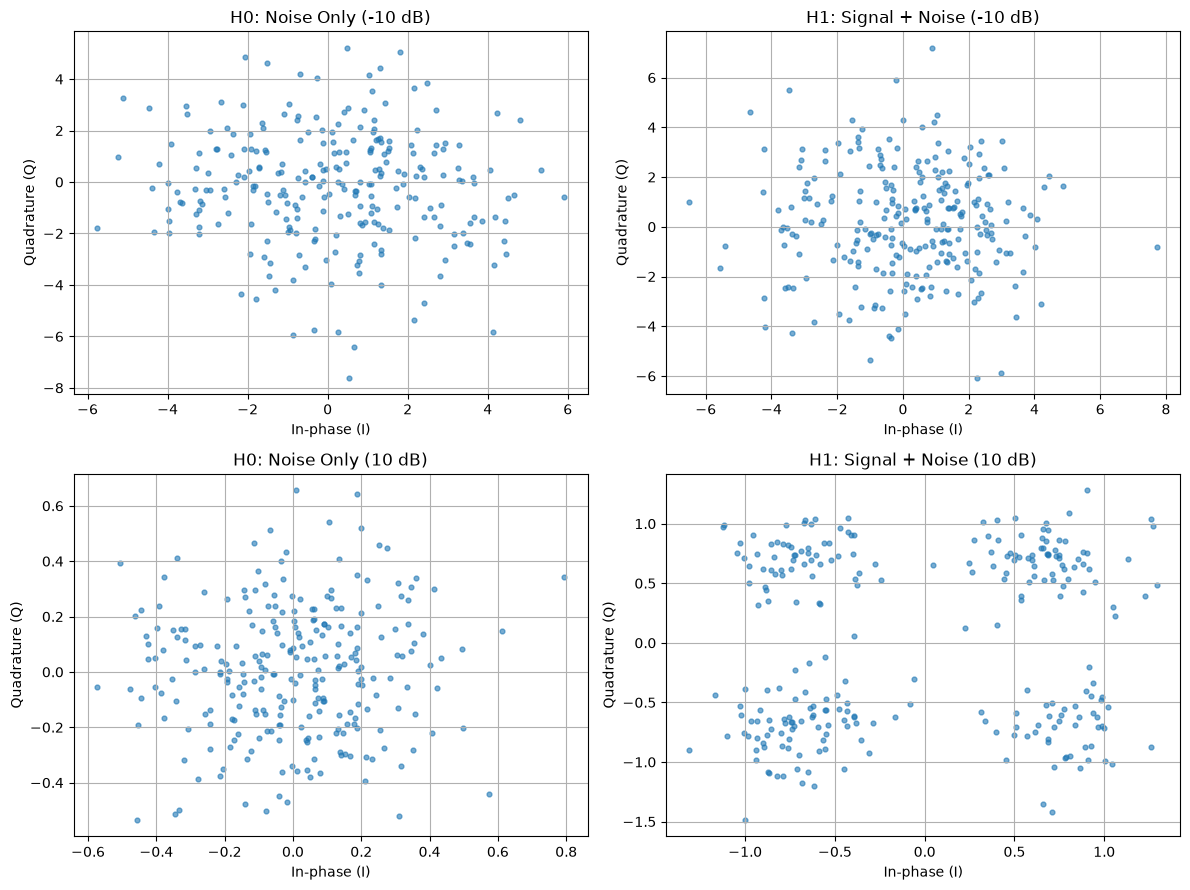

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

snr_to_check = [-10, 10]

for row, snr in enumerate(snr_to_check):

    # Select observations for this SNR
    h0_indices = np.where(
        (snr_data == snr) & (y_data == 0)
    )[0]

    h1_indices = np.where(
        (snr_data == snr) & (y_data == 1)
    )[0]

    h0_sample = X_data[h0_indices[0]]
    h1_sample = X_data[h1_indices[0]]

    # H0 plot
    axes[row, 0].scatter(
        h0_sample.real,
        h0_sample.imag,
        s=12,
        alpha=0.6
    )

    axes[row, 0].set_title(f"H0: Noise Only ({snr} dB)")
    axes[row, 0].set_xlabel("In-phase (I)")
    axes[row, 0].set_ylabel("Quadrature (Q)")
    axes[row, 0].grid(True)

    # H1 plot
    axes[row, 1].scatter(
        h1_sample.real,
        h1_sample.imag,
        s=12,
        alpha=0.6
    )

    axes[row, 1].set_title(f"H1: Signal + Noise ({snr} dB)")
    axes[row, 1].set_xlabel("In-phase (I)")
    axes[row, 1].set_ylabel("Quadrature (Q)")
    axes[row, 1].grid(True)

plt.tight_layout()
plt.show()

In [13]:
np.savez_compressed(
    "spectrum_sensing_dataset.npz",
    X=X_data,
    y=y_data,
    snr=snr_data
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [14]:
import os

print("File exists:", os.path.exists(
    "spectrum_sensing_dataset.npz"
))

print("File size:",
      round(os.path.getsize("spectrum_sensing_dataset.npz") / 1024, 2),
      "KB")

File exists: True
File size: 53935.97 KB
